Explore the data for France

In [1]:
import polars as pl

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
# For plotting with xticks
import matplotlib.dates as mdates

In [4]:
# Check the versions
print(pl.__version__)  # 2.0.0


2.0.0


In [5]:
# Load the data
df = pl.read_csv("../dat/FR_2010_2025.csv")

In [6]:
dir(df)

['__add__',
 '__annotations__',
 '__array__',
 '__arrow_c_stream__',
 '__bool__',
 '__class__',
 '__contains__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__mod__',
 '__module__',
 '__mul__',
 '__ne__',
 '__new__',
 '__radd__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__reversed__',
 '__rmul__',
 '__setattr__',
 '__setitem__',
 '__setstate__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 '__truediv__',
 '__weakref__',
 '_accessors',
 '_cast_all_from_to',
 '_comp',
 '_compare_to_non_df',
 '_compare_to_other_df',
 '_df',
 '_div',
 '_from_arrow',
 '_from_pandas',
 '_from_pydf',
 '_import_columns',
 '_ipython_key_completions_',
 '_replace',
 '_repr_html_

Shape

In [6]:
print(df.shape)
# (194, 9)


(194, 9)


In [7]:
df.head()

Time,Python,C++,Java,C#,JavaScript,Visual Basic,Structured Query Language,Rust
str,i64,i64,i64,i64,i64,i64,i64,i64
"""2009-12-01""",13,16,79,14,39,11,36,0
"""2010-01-01""",15,19,77,15,40,11,37,0
"""2010-02-01""",15,21,80,16,42,11,42,0
"""2010-03-01""",14,21,91,16,42,12,42,0
"""2010-04-01""",14,18,84,16,42,12,39,0


In [8]:
# Replace 'Structured Query Language' -> 'SQL'
df =df.rename({"Structured Query Language": "SQL"}, strict=True)

In [9]:
df.head()

Time,Python,C++,Java,C#,JavaScript,Visual Basic,SQL,Rust
str,i64,i64,i64,i64,i64,i64,i64,i64
"""2009-12-01""",13,16,79,14,39,11,36,0
"""2010-01-01""",15,19,77,15,40,11,37,0
"""2010-02-01""",15,21,80,16,42,11,42,0
"""2010-03-01""",14,21,91,16,42,12,42,0
"""2010-04-01""",14,18,84,16,42,12,39,0


Convert the column "Time" to the type of date.

In [10]:
# Convert the column "Time" to the type of date.
df = df.with_columns(pl.col("Time").str.to_date())


In [11]:
df.head()

Time,Python,C++,Java,C#,JavaScript,Visual Basic,SQL,Rust
date,i64,i64,i64,i64,i64,i64,i64,i64
2009-12-01,13,16,79,14,39,11,36,0
2010-01-01,15,19,77,15,40,11,37,0
2010-02-01,15,21,80,16,42,11,42,0
2010-03-01,14,21,91,16,42,12,42,0
2010-04-01,14,18,84,16,42,12,39,0


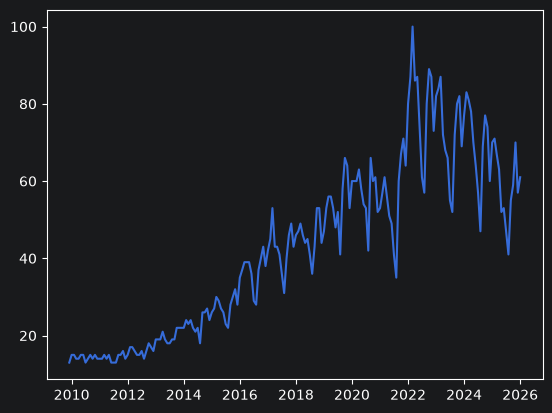

In [12]:
# Plot the data for Python.
plt.plot(df["Time"], df["Python"])

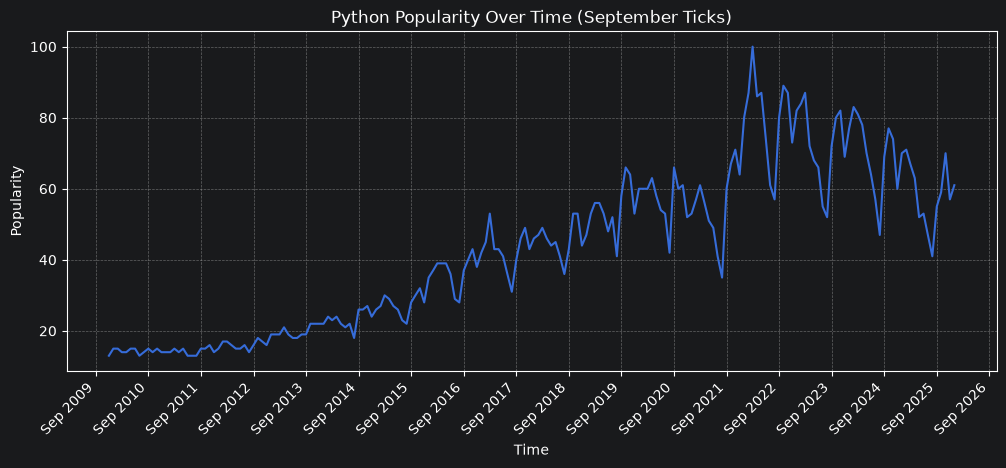

In [13]:
# Replot the data, indicating September of each year.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df["Time"], df["Python"], label="Python")

# x-axis
# ax.xaxis.set_major_locator(plt.MultipleLocator(365))

# Set major ticks to September of each year (month=9)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=9))

# Format the tick labels, e.g. "Sep 2020" or "2020-09"
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Rotate and align date tick labels nicely
fig.autofmt_xdate(rotation=45)

ax.set_title("Python Popularity Over Time (September Ticks)")
ax.set_xlabel("Time")
ax.set_ylabel("Popularity")
ax.grid(True, linestyle="--", alpha=0.5)


As expected, the plot shows sesonal fluctuations. The data is plotted for each month, but the x-axis labels are set to show only the month of September for each year.

This makes it easier to see the popularity of Python drops during summer,
then surges at the beginning of each school-year.